In [1]:
import os

print(os.listdir("/kaggle/input"))

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file == "Train.csv" or file == "Test.csv":
            print(os.path.join(root, file))


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import os

from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras import layers, models

['datasets']
/kaggle/input/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign/Test.csv
/kaggle/input/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign/Train.csv


I0000 00:00:1794903801.683344      50 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794903819.516004      50 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:

path = "/kaggle/input/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign"

train = pd.read_csv(path + "/Train.csv")
test = pd.read_csv(path + "/Test.csv")

print("Навчальні дані:", train.shape)
print("Тестові дані:", test.shape)

train.head()

Навчальні дані: (39209, 8)
Тестові дані: (12630, 8)


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png


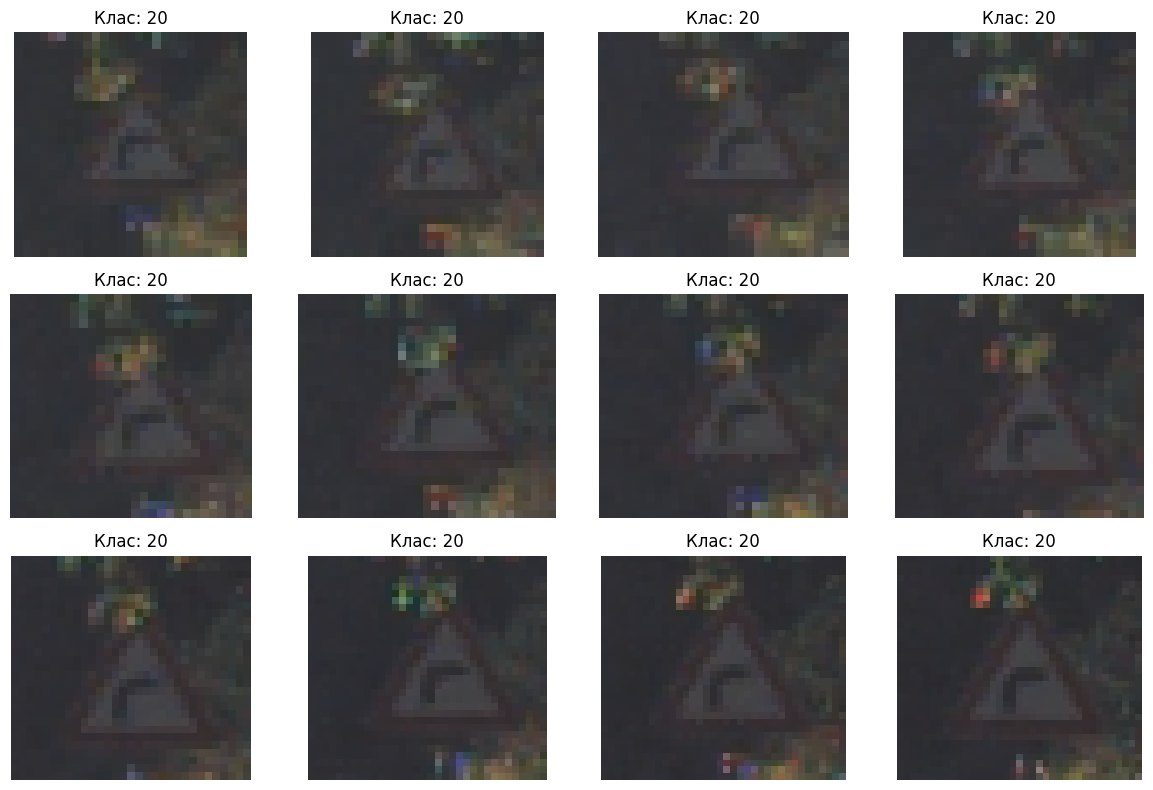

In [3]:
plt.figure(figsize=(12, 8))

for i in range(12):
    img = Image.open(path + "/" + train["Path"][i])

    plt.subplot(3, 4, i + 1)
    plt.imshow(img)
    plt.title("Клас: " + str(train["ClassId"][i]))
    plt.axis("off")

plt.tight_layout()
plt.show()

In [5]:

from tqdm.auto import tqdm

X = []
y = []

for i in tqdm(range(len(train))):
    img = Image.open(path + "/" + train["Path"][i])
    img = img.convert("RGB")
    img = img.resize((32, 32))

    X.append(np.array(img))
    y.append(train["ClassId"][i])

X = np.array(X, dtype="float32") / 255.0
y = np.array(y)

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Навчальна вибірка:", X_train.shape)
print("Валідаційна вибірка:", X_val.shape)

  0%|          | 0/39209 [00:00<?, ?it/s]

Навчальна вибірка: (31367, 32, 32, 3)
Валідаційна вибірка: (7842, 32, 32, 3)


In [6]:
model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(43, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

E0000 00:00:1794904982.647990      50 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │         5,547 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 361,067 (1.38 MB)

 Trainable params: 361,067 (1.38 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
history = model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=64,
    validation_data=(X_val, y_val)
)

Epoch 1/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 26s 49ms/step - accuracy: 0.6123 - loss: 1.4103 - val_accuracy: 0.9172 - val_loss: 0.3042
Epoch 2/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 23s 47ms/step - accuracy: 0.9135 - loss: 0.3037 - val_accuracy: 0.9649 - val_loss: 0.1295
Epoch 3/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 23s 47ms/step - accuracy: 0.9530 - loss: 0.1621 - val_accuracy: 0.9790 - val_loss: 0.0784
Epoch 4/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 24s 49ms/step - accuracy: 0.9685 - loss: 0.1059 - val_accuracy: 0.9842 - val_loss: 0.0636
Epoch 5/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 23s 47ms/step - accuracy: 0.9780 - loss: 0.0747 - val_accuracy: 0.9894 - val_loss: 0.0459
Epoch 6/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 23s 47ms/step - accuracy: 0.9805 - loss: 0.0641 - val_accuracy: 0.9921 - val_loss: 0.0370
Epoch 7/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 23s 47ms/step - accuracy: 0.9857 - loss: 0.0469 - val_accuracy: 0.9912 - val_loss: 0.0415
Epoch 8/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 23s 47ms/step - accuracy: 0.9876 - loss: 0.0403 - 

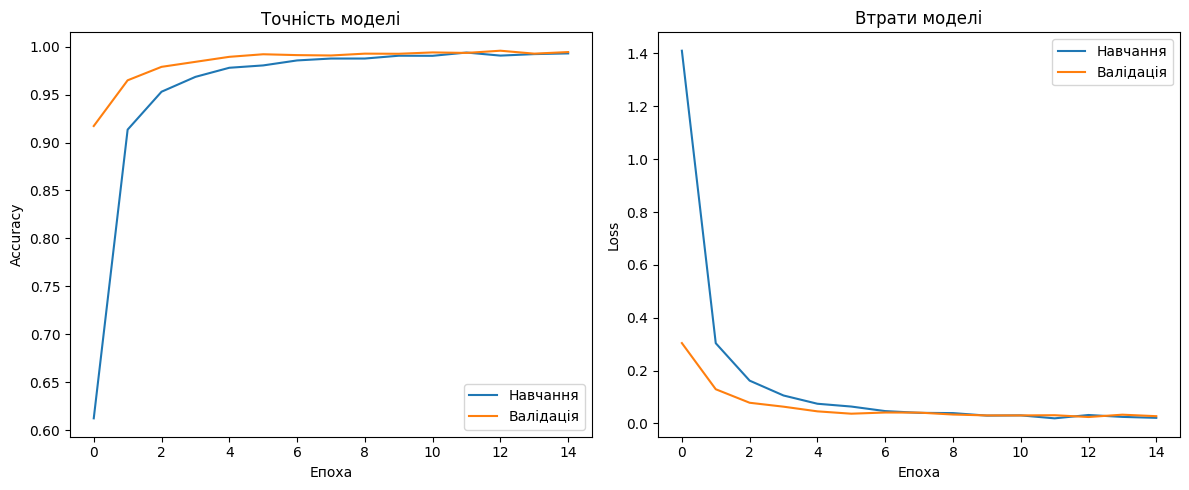

In [8]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Навчання")
plt.plot(history.history["val_accuracy"], label="Валідація")
plt.title("Точність моделі")
plt.xlabel("Епоха")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Навчання")
plt.plot(history.history["val_loss"], label="Валідація")
plt.title("Втрати моделі")
plt.xlabel("Епоха")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [10]:

from tqdm.auto import tqdm

X_test = []
y_test = []

for i in tqdm(range(len(test)), desc="Завантаження тестових даних"):
    img = Image.open(path + "/" + test["Path"][i])
    img = img.convert("RGB")
    img = img.resize((32, 32))

    X_test.append(np.array(img))
    y_test.append(test["ClassId"][i])

X_test = np.array(X_test, dtype="float32") / 255.0
y_test = np.array(y_test)

loss, accuracy = model.evaluate(X_test, y_test, verbose=1)

print("Точність на тестових даних:", accuracy)
print("Втрати на тестових даних:", loss)

Завантаження тестових даних:   0%|          | 0/12630 [00:00<?, ?it/s]

395/395 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9549 - loss: 0.2733
Точність на тестових даних: 0.9548693299293518
Втрати на тестових даних: 0.27327021956443787


395/395 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step


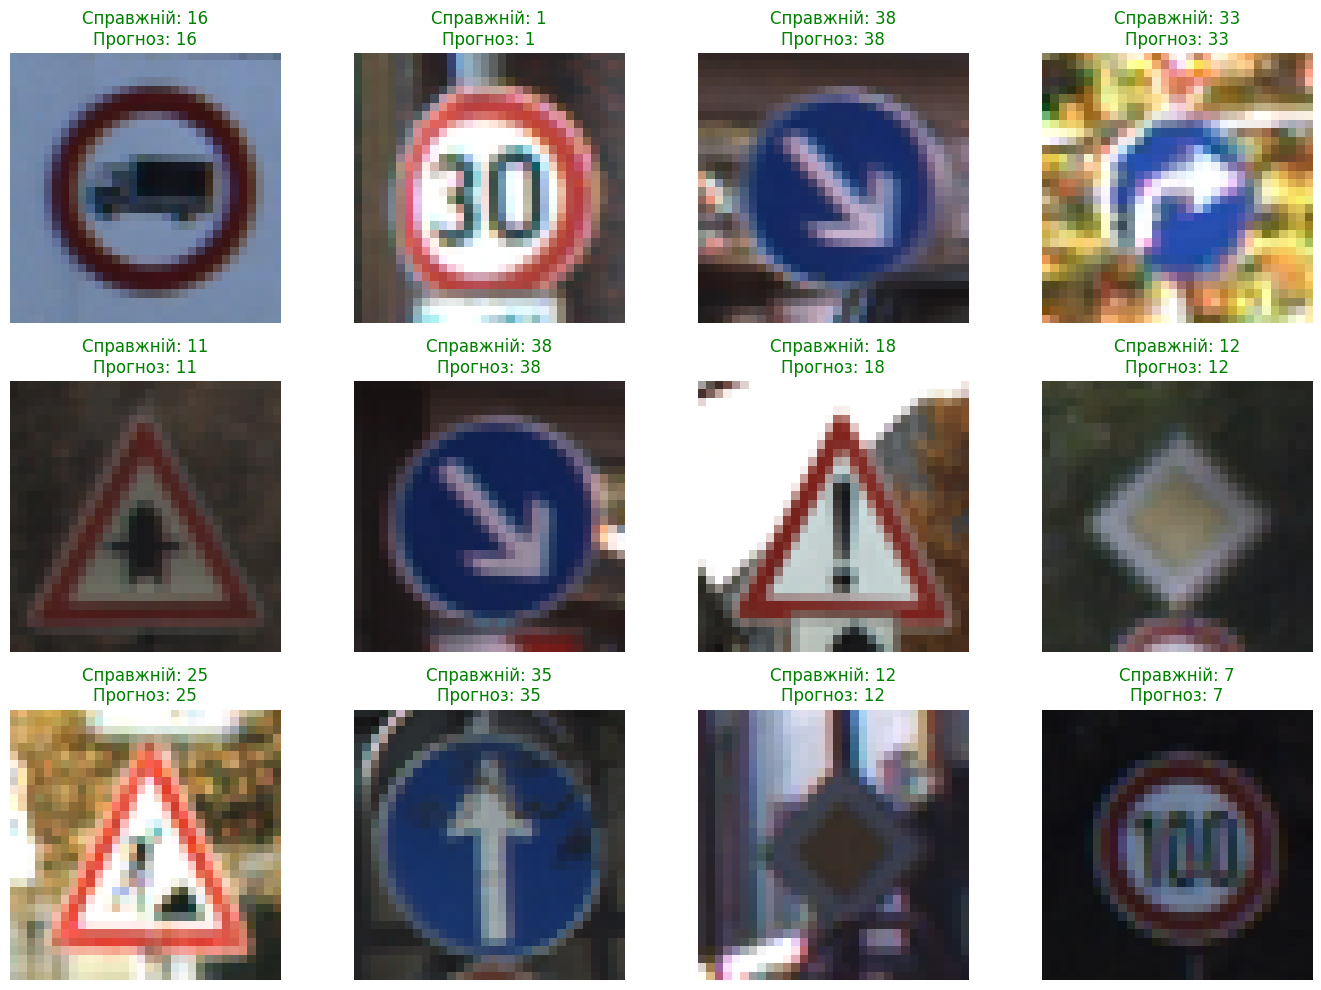

In [11]:
predictions = model.predict(X_test)
predicted_classes = np.argmax(predictions, axis=1)

plt.figure(figsize=(14, 10))

for i in range(12):
    plt.subplot(3, 4, i + 1)

    plt.imshow(X_test[i])

    true_class = y_test[i]
    predicted_class = predicted_classes[i]

    color = "green" if true_class == predicted_class else "red"

    plt.title(
        f"Справжній: {true_class}\nПрогноз: {predicted_class}",
        color=color
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

           0       0.97      0.93      0.95        60
           1       0.94      0.99      0.97       720
           2       0.96      0.98      0.97       750
           3       0.98      0.97      0.98       450
           4       0.99      0.96      0.97       660
           5       0.96      0.93      0.95       630
           6       0.98      0.83      0.90       150
           7       0.98      0.90      0.94       450
           8       0.89      0.97      0.93       450
           9       0.95      0.99      0.97       480
          10       0.98      0.98      0.98       660
          11       0.95      0.90      0.92       420
          12       0.97      0.99      0.98       690
          13       0.99      1.00      0.99       720
          14       1.00      1.00      1.00       270
          15       0.94      1.00      0.97       210
          16       0.99      0.99      0.99       150
          17       1.00    

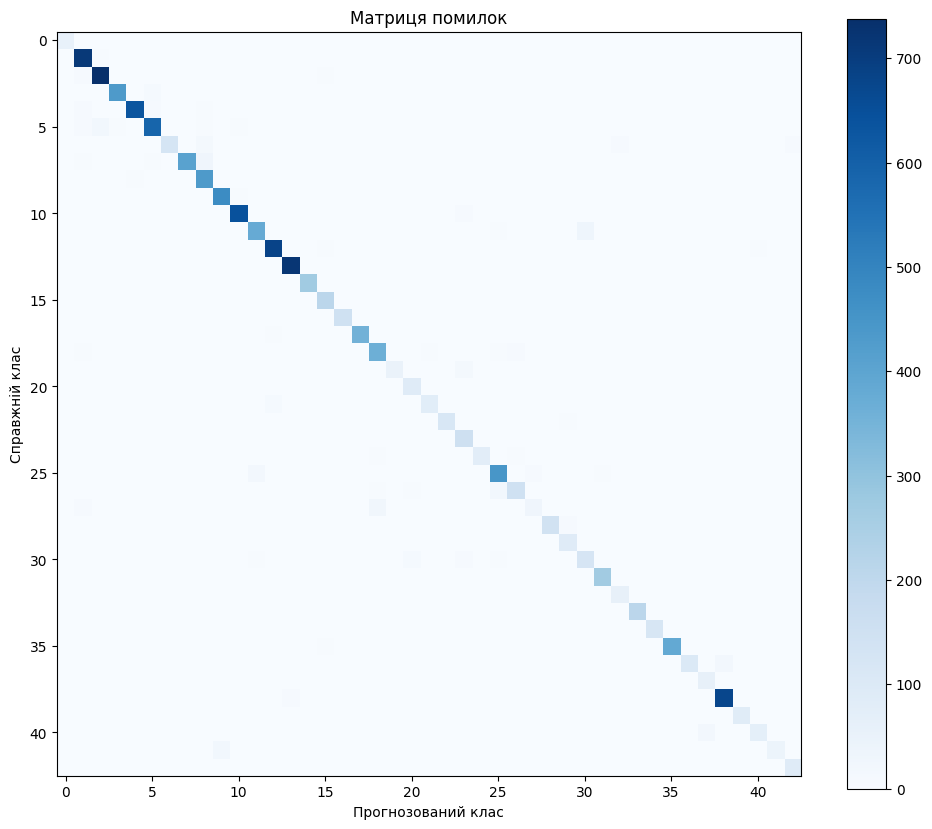

In [12]:
print(classification_report(
    y_test,
    predicted_classes,
    zero_division=0
))

cm = confusion_matrix(y_test, predicted_classes)

plt.figure(figsize=(12, 10))
plt.imshow(cm, cmap="Blues")
plt.colorbar()

plt.title("Матриця помилок")
plt.xlabel("Прогнозований клас")
plt.ylabel("Справжній клас")

plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step


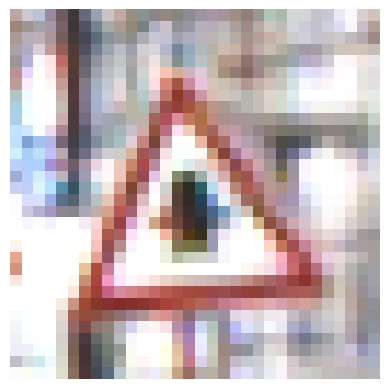

Справжній клас: 11
Прогнозований клас: 11
Впевненість моделі: 100.0 %


In [13]:
i = 25

img = X_test[i]
prediction = model.predict(np.expand_dims(img, axis=0))

predicted_class = np.argmax(prediction)
confidence = np.max(prediction) * 100

plt.imshow(img)
plt.axis("off")
plt.show()

print("Справжній клас:", y_test[i])
print("Прогнозований клас:", predicted_class)
print("Впевненість моделі:", round(confidence, 2), "%")